In [1]:
#import packages needed
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
heart_df = pd.read_csv('Hearts.csv')
heart_df.head()

,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No


In [3]:
#shape of heart_df
heart_df.shape

(303, 15)

In [4]:
heart_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  303 non-null    int64  
 1   Age         303 non-null    int64  
 2   Sex         303 non-null    int64  
 3   ChestPain   303 non-null    object 
 4   RestBP      303 non-null    int64  
 5   Chol        303 non-null    int64  
 6   Fbs         303 non-null    int64  
 7   RestECG     303 non-null    int64  
 8   MaxHR       303 non-null    int64  
 9   ExAng       303 non-null    int64  
 10  Oldpeak     303 non-null    float64
 11  Slope       303 non-null    int64  
 12  Ca          299 non-null    float64
 13  Thal        301 non-null    object 
 14  AHD         303 non-null    object 
dtypes: float64(2), int64(10), object(3)
memory usage: 35.6+ KB


In [5]:
#check for missing values
heart_df.isna().sum()

Unnamed: 0    0
Age           0
Sex           0
ChestPain     0
RestBP        0
Chol          0
Fbs           0
RestECG       0
MaxHR         0
ExAng         0
Oldpeak       0
Slope         0
Ca            4
Thal          2
AHD           0
dtype: int64

In [6]:
#remove the 4 patients with no Ca value (matches the tutorial's database import)
heart_df = heart_df.dropna(subset=['Ca'])
heart_df.shape

(299, 15)

In [7]:
#check for the number of unique ages in the age category
print('Count of unique ages :', heart_df['Age'].nunique())

print('\n')
#check for the unique ages in the age category
print('unique ages :', heart_df['Age'].unique())

Count of unique ages : 41


unique ages : [63 67 37 41 56 62 57 53 44 52 48 54 49 64 58 60 50 66 43 40 69 59 42 55
 61 65 71 51 46 45 39 68 47 34 35 29 70 77 38 74 76]


In [8]:
#Explore the Age column using the describe function
print(heart_df['Age'].describe())

print('\n')

#create bins for the various age categories
twenty_fifth = heart_df['Age'].quantile(0.25)
median = heart_df['Age'].median()
seventy_fifth = heart_df['Age'].quantile(0.75)
maximum = heart_df['Age'].max()

#create a label and bins for the various age categories
labels = ['29-48','49-56','57-61','62-77']
bins = [0, twenty_fifth, median, seventy_fifth, maximum]

#create a category column for age
heart_df['Age_cat'] = pd.cut(heart_df['Age'], labels=labels, bins=bins)

count    299.000000
mean      54.528428
std        9.020950
min       29.000000
25%       48.000000
50%       56.000000
75%       61.000000
max       77.000000
Name: Age, dtype: float64




In [9]:
#show table showing the Age and Age_cat columns side by side
heart_df[['Age','Age_cat']]

,Age,Age_cat
0,63,62-77
1,67,62-77
2,67,62-77
3,37,29-48
4,41,29-48
...,...,...
297,57,57-61
298,45,29-48
299,68,62-77
300,57,57-61


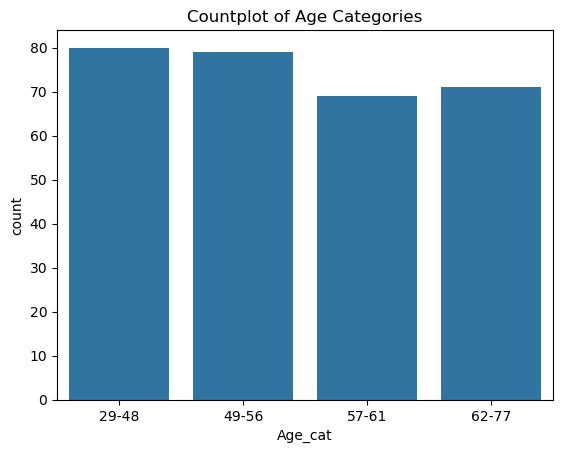

In [10]:
#visualization of the Age_cat column
sns.countplot(x='Age_cat',data=heart_df)
plt.title('Countplot of Age Categories')
plt.show()

In [11]:
#read data
heart_df.head()

,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD,Age_cat
0,1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No,62-77
1,2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes,62-77
2,3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes,62-77
3,4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No,29-48
4,5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No,29-48


In [12]:
#create categorical column for sex and angina by exercise(ExAng) columns
heart_df['Sex_cat'] = np.where(heart_df['Sex']==1, 'Male','Female')
heart_df['ExAng_cat'] = np.where(heart_df['ExAng']==1, 'yes','no')

heart_df.head()

,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD,Age_cat,Sex_cat,ExAng_cat
0,1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No,62-77,Male,no
1,2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes,62-77,Male,yes
2,3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes,62-77,Male,yes
3,4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No,29-48,Male,no
4,5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No,29-48,Female,no


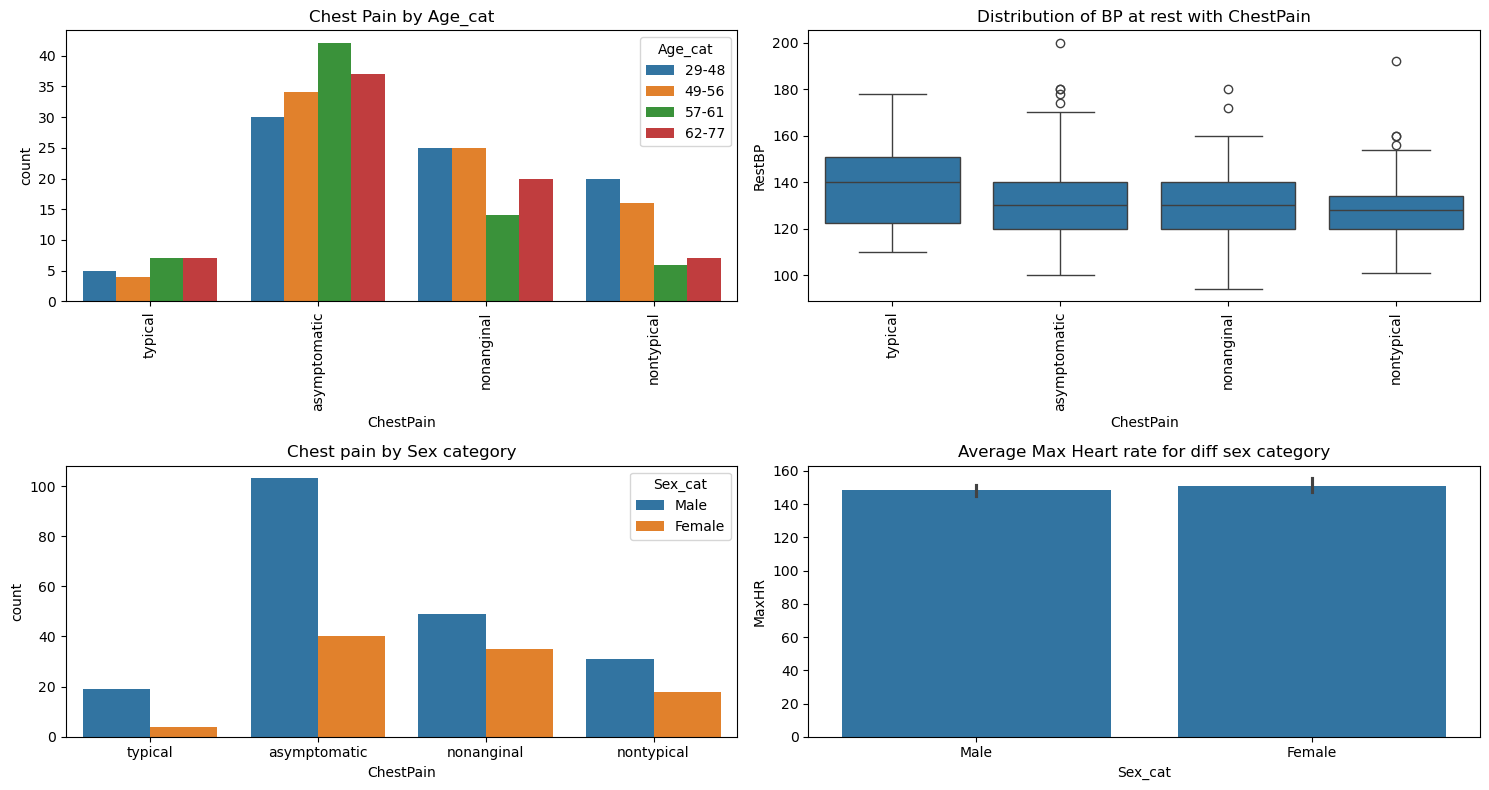

In [13]:
#exploring the various categorical columns

fig, axs = plt.subplots(nrows=2, ncols=2, sharey=False, figsize=(15,8))
fig.subplots_adjust(hspace=0.5)

g = sns.countplot(x='ChestPain', hue='Age_cat', data=heart_df, ax=axs[0,0])
g.set_title('Chest Pain by Age_cat')
axs[0,0].tick_params(axis='x', rotation=90)

g = sns.boxplot(x='ChestPain', y='RestBP', data=heart_df, ax=axs[0,1])
g.set_title('Distribution of BP at rest with ChestPain')
axs[0,1].tick_params(axis='x', rotation=90)

g = sns.countplot(x='ChestPain', hue='Sex_cat', data=heart_df, ax=axs[1,0])
g.set_title('Chest pain by Sex category')

g = sns.barplot(y='MaxHR', x='Sex_cat', data=heart_df, ax=axs[1,1])
g.set_title('Average Max Heart rate for diff sex category')

fig.tight_layout()
plt.savefig('chest_pain_overview.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
#value counting various age categories for sex
age_cat_count = heart_df[['Sex_cat','Age_cat']].value_counts(normalize=True, sort=True).to_frame()
age_cat_count

proportion
Sex_cat Age_cat            
Male    29-48      0.193980
        49-56      0.180602
        57-61      0.170569
        62-77      0.130435
Female  62-77      0.107023
        49-56      0.083612
        29-48      0.073579
        57-61      0.060201

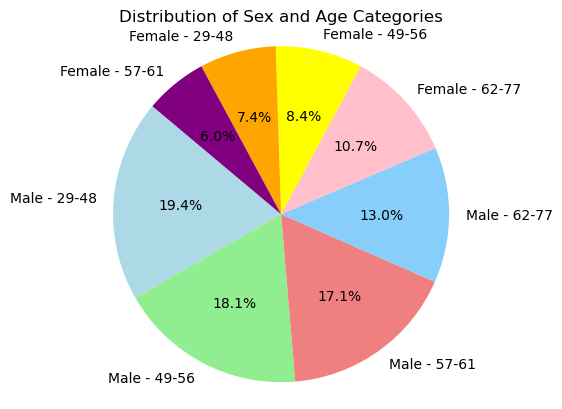

In [15]:
# Data for the pie chart
sex_age_data = heart_df[['Sex_cat','Age_cat']].value_counts(normalize=True).to_dict()

# Create a figure and axis
fig, ax = plt.subplots()

# Data for the pie chart
labels = [f"{sex} - {age}" for sex, age in sex_age_data.keys()]
sizes = list(sex_age_data.values())

# Colors for the pie chart
colors = ['lightblue', 'lightgreen', 'lightcoral', 'lightskyblue', 'pink', 'yellow', 'orange', 'purple']

# Plot the pie chart
ax.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=140)

# Aspect ratio to make the pie circular
ax.axis('equal')

# Title for the pie chart
plt.title('Distribution of Sex and Age Categories')

# Show the pie chart
plt.show()

In [16]:
#describing the categorical columns
heart_df.describe(exclude=[np.number])

,ChestPain,Thal,AHD,Age_cat,Sex_cat,ExAng_cat
count,299,297,299,299,299,299
unique,4,3,2,4,2,2
top,asymptomatic,normal,No,29-48,Male,no
freq,143,164,161,80,202,201


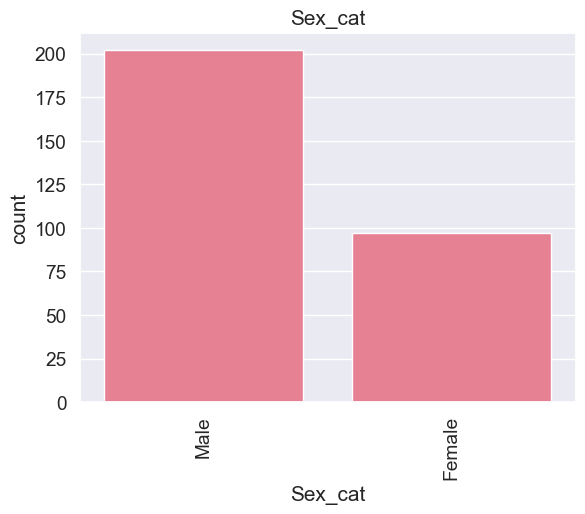

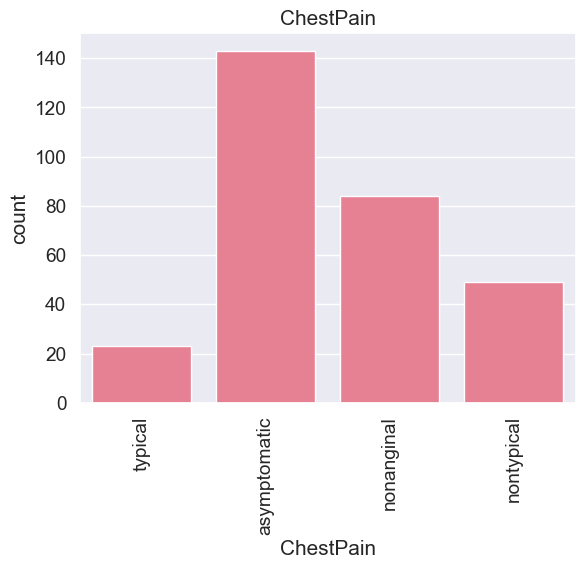

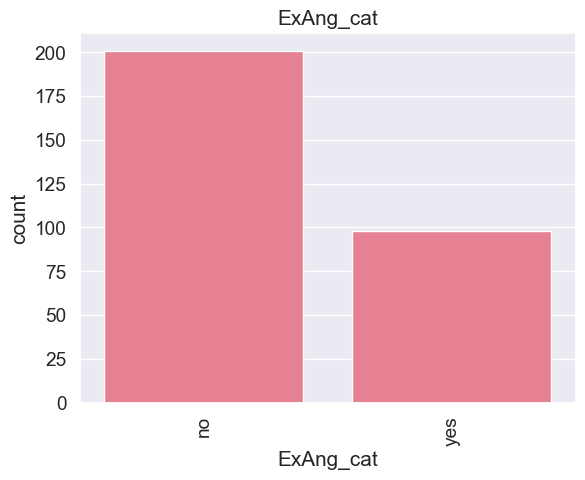

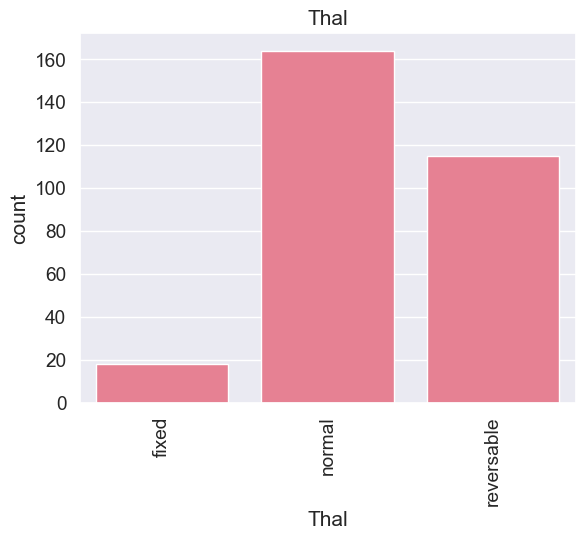

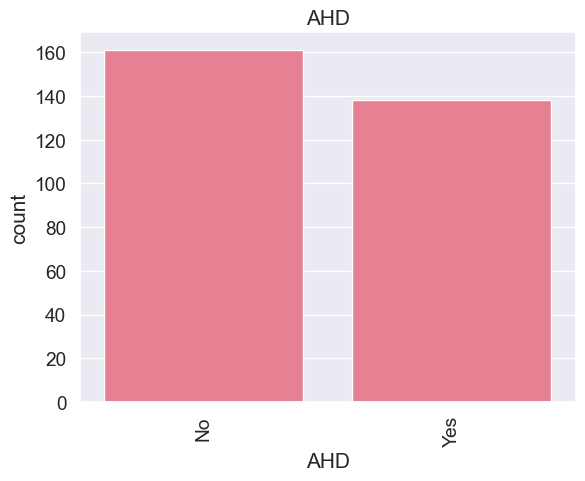

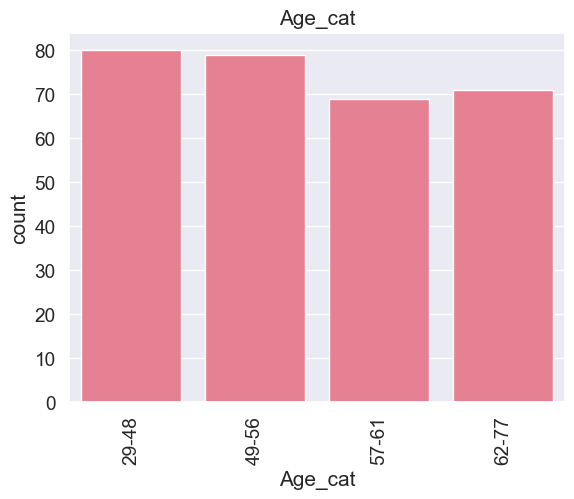

In [17]:
#visualize the information above for easy understanding
#value counting the categorical columns

columns = ['Sex_cat', 'ChestPain', 'ExAng_cat', 'Thal', 'AHD', 'Age_cat']

sns.set(style='darkgrid', font_scale=1.25)
sns.set_palette('husl', 3)

def plot_cat_count():
    for c in columns:
        sns.countplot(x=c, data=heart_df)
        plt.title(c)
        plt.xticks(rotation=90)
        plt.show()

plot_cat_count()

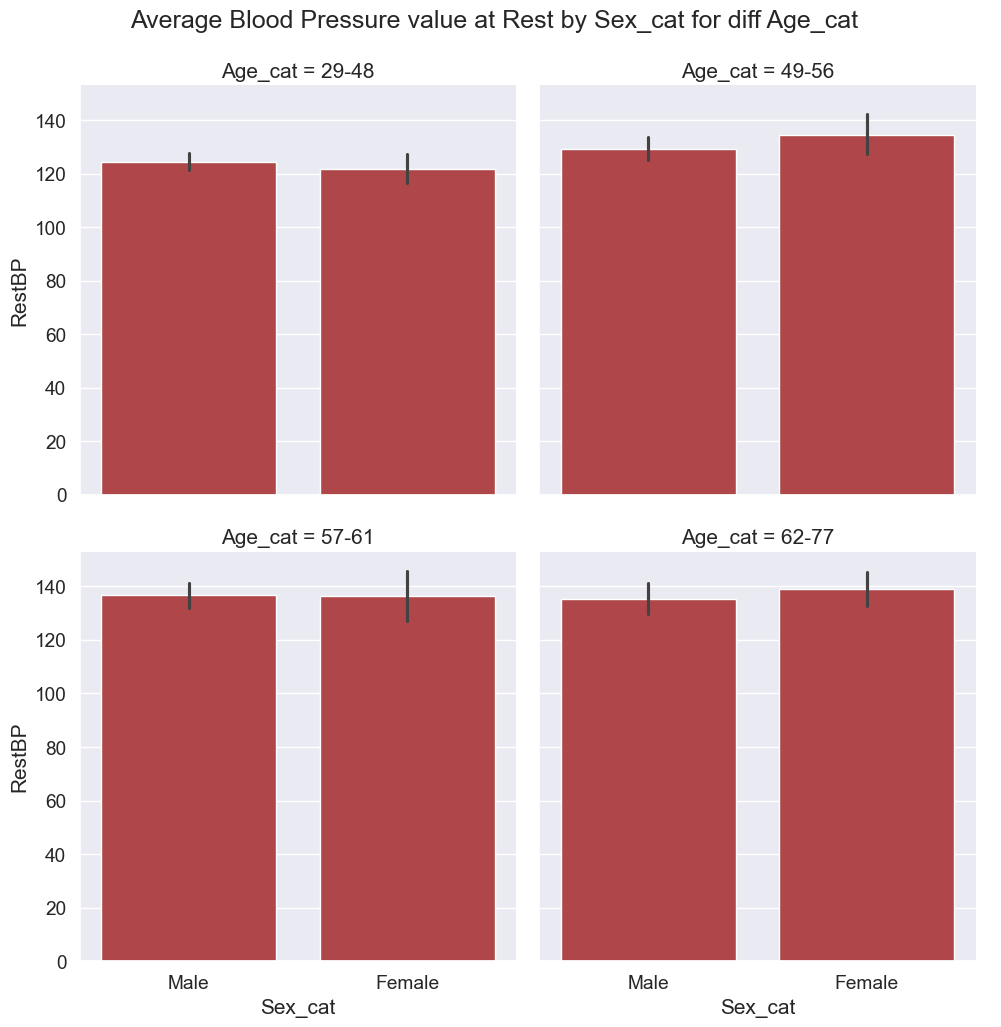

In [18]:
#visualizing Blood pressure at rest by Sex for the different age categories
sns.set_palette('RdBu')
g = sns.catplot(x='Sex_cat', y='RestBP', data=heart_df, kind='bar', col='Age_cat', col_wrap=2)
g.fig.suptitle('Average Blood Pressure value at Rest by Sex_cat for diff Age_cat', y=1.03)
plt.savefig('restbp_by_sex_age.png', dpi=150, bbox_inches='tight')
plt.show()

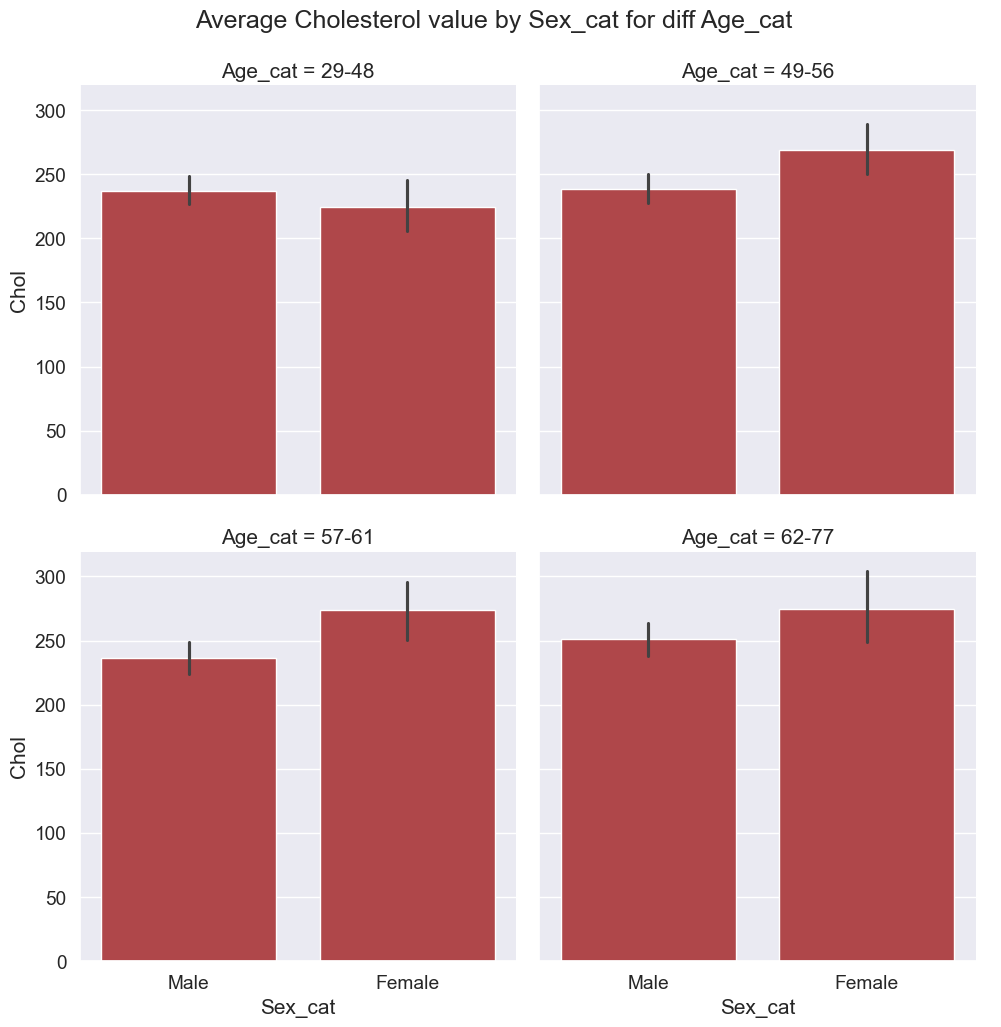

In [19]:
#visualizing Cholesterol by Sex for the different age categories
sns.set_palette('RdBu')
g = sns.catplot(x='Sex_cat', y='Chol', data=heart_df, kind='bar', col='Age_cat', col_wrap=2)
g.fig.suptitle('Average Cholesterol value by Sex_cat for diff Age_cat', y=1.03)
plt.savefig('cholesterol_by_sex_age.png', dpi=150, bbox_inches='tight')
plt.show()

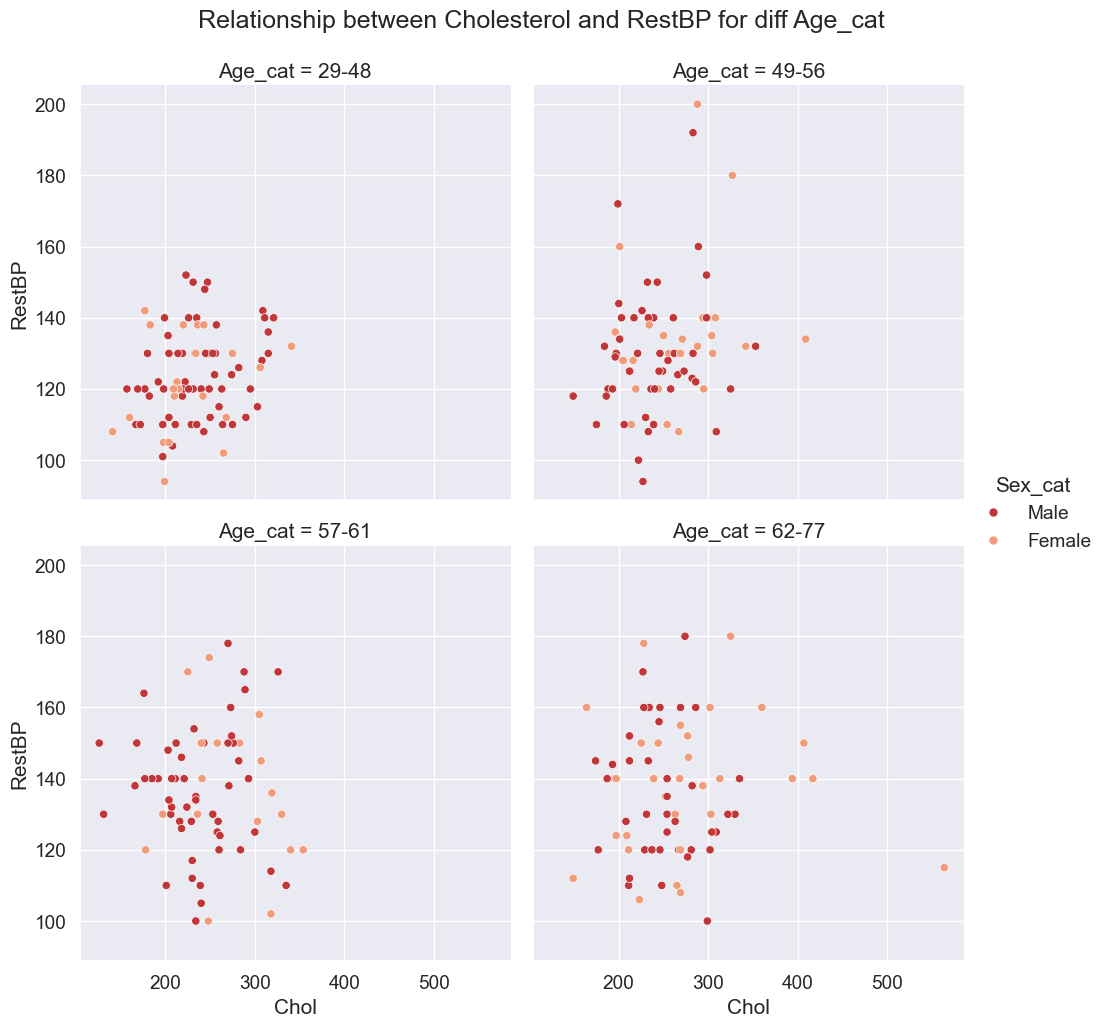

In [20]:
#visualizing RestBP by Chol for the different age categories
sns.set_style('darkgrid')
g = sns.relplot(x='Chol', y='RestBP', data=heart_df, hue='Sex_cat', col='Age_cat', col_wrap=2)
g.fig.suptitle('Relationship between Cholesterol and RestBP for diff Age_cat', y=1.03)
plt.show()

In [21]:
#drop the unnamed column
heart_df.drop(columns=['Unnamed: 0'], inplace=True)

#checking for the types of the data column

heart_df.describe()

,Age,Sex,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000
mean,54.528428,0.675585,131.668896,247.100334,0.147157,0.996656,149.505017,0.327759,1.051839,1.602007,0.672241
std,9.020950,0.468941,17.705668,51.914779,0.354856,0.994948,22.954927,0.470183,1.163809,0.617526,0.937438
min,29.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000
25%,48.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.000000,0.000000,0.000000,1.000000,0.000000
50%,56.000000,1.000000,130.000000,242.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000
75%,61.000000,1.000000,140.000000,275.500000,0.000000,2.000000,165.500000,1.000000,1.600000,2.000000,1.000000
max,77.000000,1.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000


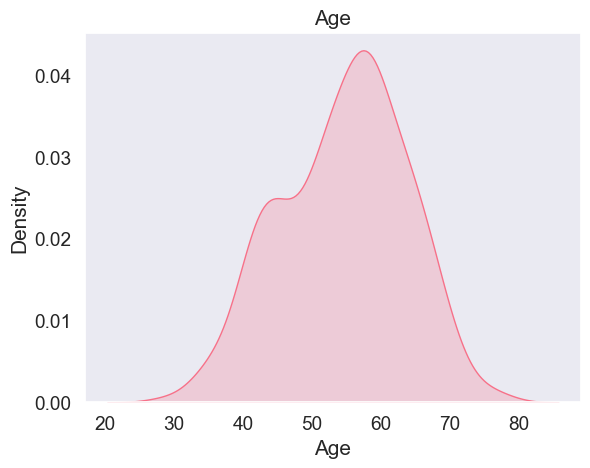

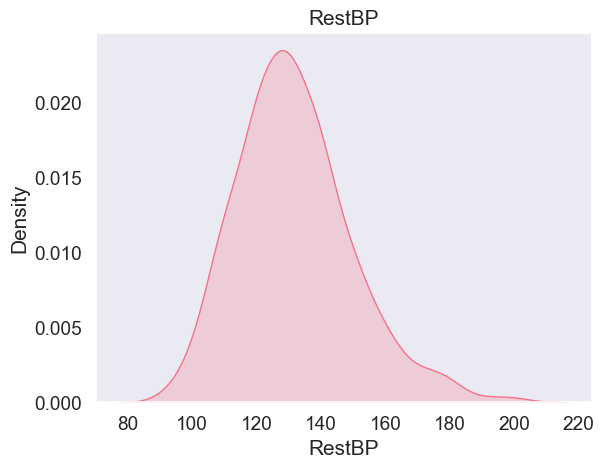

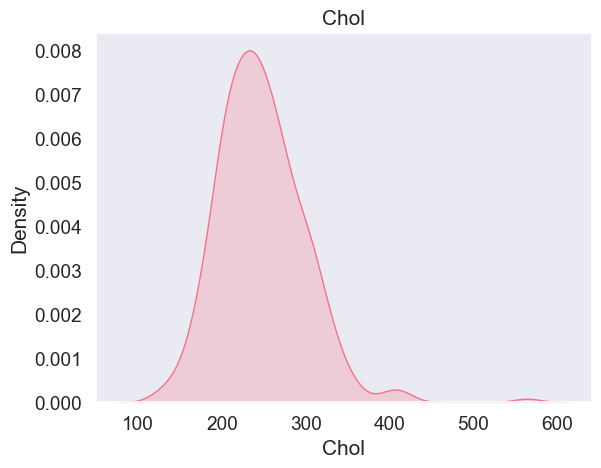

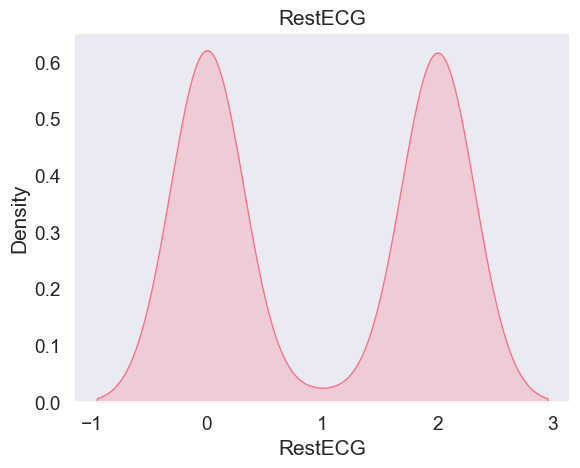

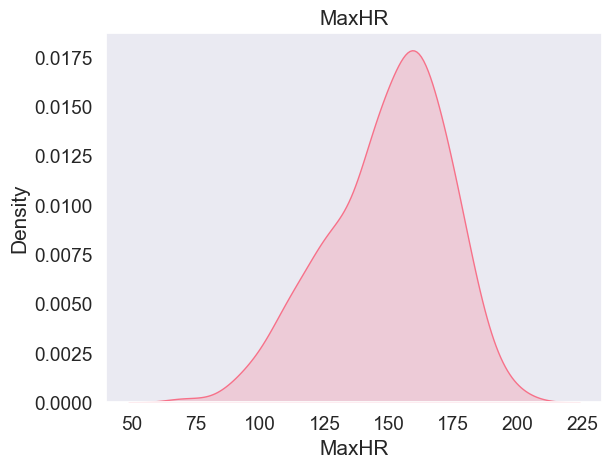

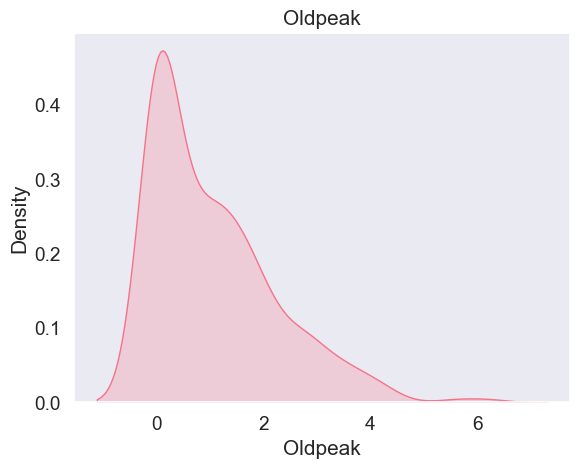

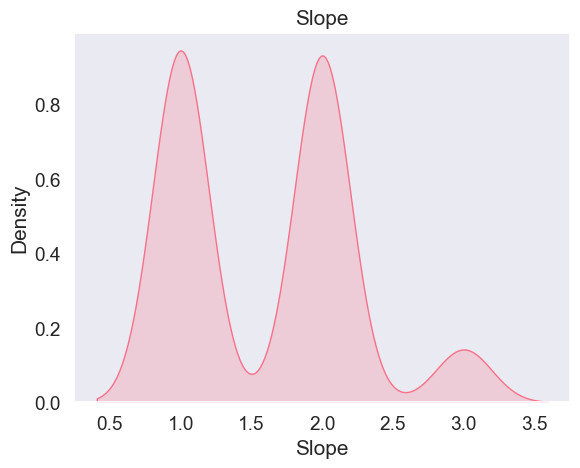

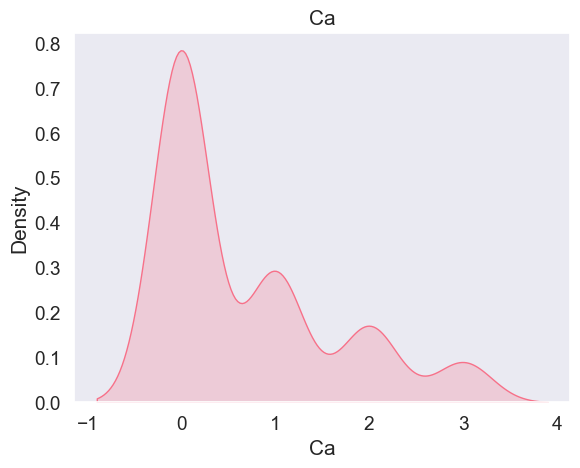

In [22]:
#visualize the information above for easy understanding
#value counting the categorical columns

columns = ['Age', 'RestBP', 'Chol', 'RestECG', 'MaxHR', 'Oldpeak', 'Slope', 'Ca']

sns.set(style='dark', font_scale=1.25)
sns.set_palette('husl', 3)

def plot_dist_count():
    for c in columns:
        #sns.distplot(heart_df[c], kde=True)
        sns.kdeplot(heart_df[c], fill=True)
        plt.title(c)
        plt.show()

plot_dist_count()

In [23]:
#checking for the variance
columns = ['Age', 'RestBP', 'Chol', 'RestECG', 'MaxHR', 'Oldpeak', 'Slope', 'Ca']

heart_df[columns].var()

Age          81.377545
RestBP      313.490674
Chol       2695.144262
RestECG       0.989922
MaxHR       526.928666
Oldpeak       1.354451
Slope         0.381338
Ca            0.878791
dtype: float64

In [24]:
#normalizing to scale the columns with high variance
heart_df[['Age', 'RestBP', 'Chol', 'MaxHR']] = np.log(heart_df[['Age', 'RestBP', 'Chol', 'MaxHR']])

#checking variance after scaling
columns = ['Age', 'RestBP', 'Chol', 'RestECG', 'MaxHR', 'Oldpeak', 'Slope', 'Ca']
heart_df[columns].var()

Age        0.030122
RestBP     0.017262
Chol       0.041527
RestECG    0.989922
MaxHR      0.027298
Oldpeak    1.354451
Slope      0.381338
Ca         0.878791
dtype: float64

In [25]:
Columns = ['Age', 'Sex', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'MaxHR', 'ExAng', 'Oldpeak', 'Slope', 'Ca']

X_val = heart_df[['Age', 'Sex', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'MaxHR', 'ExAng', 'Oldpeak', 'Slope', 'Ca']].values

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_val)

print(X_scaled)

[[ 0.9170957   0.69296322  0.80169126 ...  1.07427684  2.26765706
  -0.71830622]
 [ 1.27237613  0.69296322  1.55220299 ...  0.38572641  0.64557701
   2.48726932]
 [ 1.27237613  0.69296322 -0.64109862 ...  1.33248325  0.64557701
   1.41874414]
 ...
 [ 1.35788117  0.69296322  0.74892948 ...  2.02103367  0.64557701
   1.41874414]
 [ 0.33946556  0.69296322 -0.03084926 ...  0.12752     0.64557701
   0.35021896]
 [ 0.33946556 -1.44307804 -0.03084926 ... -0.90530564  0.64557701
   0.35021896]]


In [26]:
#creating the scaled dataframe as df
df = pd.DataFrame(data=X_scaled, columns=Columns)
df

,Age,Sex,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca
0,0.917096,0.692963,0.801691,-0.186270,2.407375,1.010130,0.098233,-0.698257,1.074277,2.267657,-0.718306
1,1.272376,0.692963,1.552203,0.821160,-0.415390,1.010130,-1.893376,1.432138,0.385726,0.645577,2.487269
2,1.272376,0.692963,-0.641099,-0.271388,-0.415390,1.010130,-0.816155,1.432138,1.332483,0.645577,1.418744
3,-2.154585,0.692963,-0.030849,0.159885,-0.415390,-1.003395,1.434888,-0.698257,2.107102,2.267657,-0.718306
4,-1.562119,-1.443078,-0.030849,-0.839619,-0.415390,1.010130,0.927963,-0.698257,0.299658,-0.976503,-0.718306
...,...,...,...,...,...,...,...,...,...,...,...
294,0.339466,-1.443078,0.534153,-0.020333,-0.415390,-1.003395,-1.104908,1.432138,-0.733168,0.645577,-0.718306
295,-1.024849,0.692963,-1.304477,0.427717,-0.415390,-1.003395,-0.676778,-0.698257,0.127520,0.645577,-0.718306
296,1.357881,0.692963,0.748929,-1.112080,2.407375,-1.003395,-0.276897,-0.698257,2.021034,0.645577,1.418744
297,0.339466,0.692963,-0.030849,-3.016768,-0.415390,-1.003395,-1.512635,1.432138,0.127520,0.645577,0.350219


In [27]:
#checking variane after scaling
df.var()

Age        1.003356
Sex        1.003356
RestBP     1.003356
Chol       1.003356
Fbs        1.003356
RestECG    1.003356
MaxHR      1.003356
ExAng      1.003356
Oldpeak    1.003356
Slope      1.003356
Ca         1.003356
dtype: float64

In [28]:
#read the normalized heart_df data
heart_df.head()

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD,Age_cat,Sex_cat,ExAng_cat
0,4.143135,1,typical,4.976734,5.451038,1,2,5.010635,0,2.3,3,0.0,fixed,No,62-77,Male,no
1,4.204693,1,asymptomatic,5.075174,5.655992,0,2,4.682131,1,1.5,2,3.0,normal,Yes,62-77,Male,yes
2,4.204693,1,asymptomatic,4.787492,5.433722,0,2,4.859812,1,2.6,2,2.0,reversable,Yes,62-77,Male,yes
3,3.610918,1,nonanginal,4.867534,5.521461,0,0,5.231109,0,3.5,3,0.0,normal,No,29-48,Male,no
4,3.713572,0,nontypical,4.867534,5.318120,0,2,5.147494,0,1.4,1,0.0,normal,No,29-48,Female,no


In [29]:
#drop all columns not needed
#dropping Age column and use Age_cat inplace
heart_df.drop(columns=['Sex_cat', 'ExAng_cat', 'Age'], inplace=True)

#read data
heart_df.head()

,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD,Age_cat
0,1,typical,4.976734,5.451038,1,2,5.010635,0,2.3,3,0.0,fixed,No,62-77
1,1,asymptomatic,5.075174,5.655992,0,2,4.682131,1,1.5,2,3.0,normal,Yes,62-77
2,1,asymptomatic,4.787492,5.433722,0,2,4.859812,1,2.6,2,2.0,reversable,Yes,62-77
3,1,nonanginal,4.867534,5.521461,0,0,5.231109,0,3.5,3,0.0,normal,No,29-48
4,0,nontypical,4.867534,5.318120,0,2,5.147494,0,1.4,1,0.0,normal,No,29-48


In [30]:
#using pd.get_dummies to replace variables to numerical

pd.get_dummies(heart_df)

,Sex,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,...,ChestPain_typical,Thal_fixed,Thal_normal,Thal_reversable,AHD_No,AHD_Yes,Age_cat_29-48,Age_cat_49-56,Age_cat_57-61,Age_cat_62-77
0,1,4.976734,5.451038,1,2,5.010635,0,2.3,3,0.0,...,True,True,False,False,True,False,False,False,False,True
1,1,5.075174,5.655992,0,2,4.682131,1,1.5,2,3.0,...,False,False,True,False,False,True,False,False,False,True
2,1,4.787492,5.433722,0,2,4.859812,1,2.6,2,2.0,...,False,False,False,True,False,True,False,False,False,True
3,1,4.867534,5.521461,0,0,5.231109,0,3.5,3,0.0,...,False,False,True,False,True,False,True,False,False,False
4,0,4.867534,5.318120,0,2,5.147494,0,1.4,1,0.0,...,False,False,True,False,True,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,0,4.941642,5.484797,0,0,4.812184,1,0.2,2,0.0,...,False,False,False,True,False,True,False,False,True,False
298,1,4.700480,5.575949,0,0,4.882802,0,1.2,2,0.0,...,True,False,False,True,False,True,True,False,False,False
299,1,4.969813,5.262690,1,0,4.948760,0,3.4,2,2.0,...,False,False,False,True,False,True,False,False,False,True
300,1,4.867534,4.875197,0,0,4.744932,1,1.2,2,1.0,...,False,False,False,True,False,True,False,False,True,False


In [31]:
raw = pd.read_csv('Hearts.csv').dropna(subset=['Ca'])
raw['AHD_flag'] = (raw['AHD'] == 'Yes').astype(int)

for col in ['ChestPain', 'Sex', 'ExAng', 'Thal', 'Ca']:
    t = raw.groupby(col)['AHD_flag'].agg(['mean', 'size'])
    t.columns = ['Heart disease rate (%)', 'Patients']
    t['Heart disease rate (%)'] = (t['Heart disease rate (%)'] * 100).round(1)
    print(f'\n{col}')
    print(t)


ChestPain
              Heart disease rate (%)  Patients
ChestPain                                     
asymptomatic                    72.7       143
nonanginal                      21.4        84
nontypical                      18.4        49
typical                         30.4        23

Sex
     Heart disease rate (%)  Patients
Sex                                  
0                      25.8        97
1                      55.9       202

ExAng
       Heart disease rate (%)  Patients
ExAng                                  
0                        31.3       201
1                        76.5        98

Thal
            Heart disease rate (%)  Patients
Thal                                        
fixed                         66.7        18
normal                        22.6       164
reversable                    76.5       115

Ca
     Heart disease rate (%)  Patients
Ca                                   
0.0                    26.1       176
1.0                    67.7       

In [32]:
raw.groupby('AHD')[['Age', 'RestBP', 'Chol', 'MaxHR', 'Oldpeak']].mean().round(1)

,Age,RestBP,Chol,MaxHR,Oldpeak
AHD,,,,,
No,52.6,129.2,243.3,158.3,0.6
Yes,56.7,134.6,251.5,139.2,1.6


In [33]:
pct_max_hr = raw['MaxHR'] / (220 - raw['Age'])
raw['Reached_85pct'] = np.where(pct_max_hr >= 0.85, 'Yes', 'No')
print(raw.groupby('Reached_85pct')['AHD_flag'].agg(['mean', 'size']).round(3))

print('\nCholesterol 400+:', (raw['Chol'] >= 400).sum(), '| max:', raw['Chol'].max())
print('Resting BP 180+:', (raw['RestBP'] >= 180).sum())
print('Max HR under 100:', (raw['MaxHR'] < 100).sum())

                mean  size
Reached_85pct             
No             0.714    91
Yes            0.351   208

Cholesterol 400+: 4 | max: 564
Resting BP 180+: 5
Max HR under 100: 8


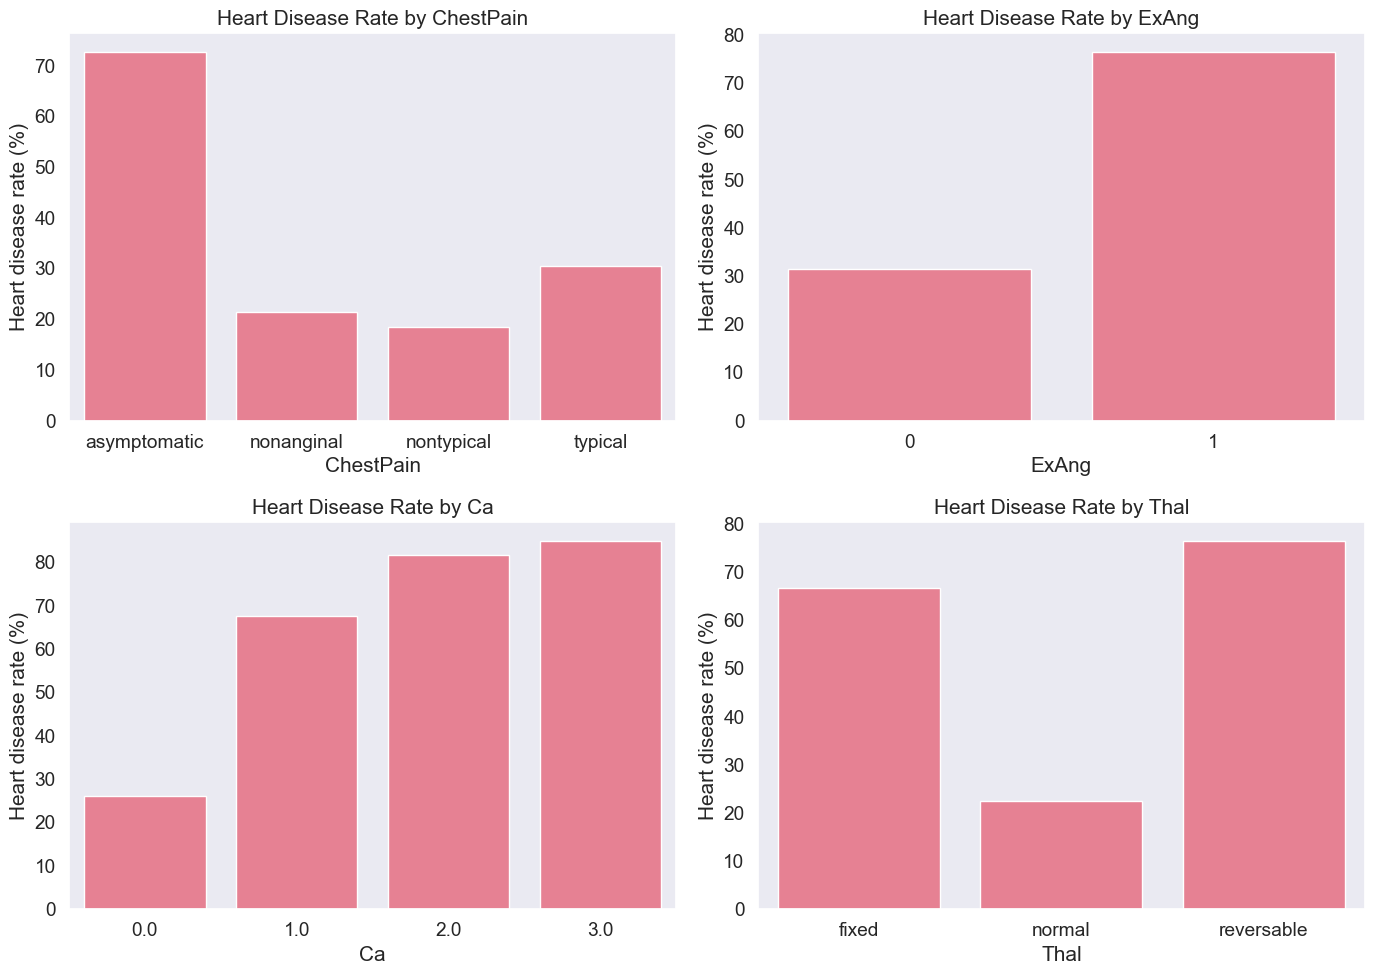

In [34]:
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axs.flat, ['ChestPain', 'ExAng', 'Ca', 'Thal']):
    rate = raw.groupby(col)['AHD_flag'].mean().mul(100)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.set_title(f'Heart Disease Rate by {col}')
    ax.set_ylabel('Heart disease rate (%)')
    ax.set_xlabel(col)
fig.tight_layout()
plt.savefig('heart_disease_rate_by_risk_factor.png', dpi=150, bbox_inches='tight')
plt.show()